# 05 · Hành vi ăn uống: biểu đồ

Notebook này **không chạy Spark**. Nó đọc các bảng nhỏ mà bước 05 (`src/05_analysis.py`) đã xuất ra
`data/output/analysis/*.json` (bản sao của `/data/results/analysis` trên HDFS), vẽ biểu đồ và lưu PNG vào
`docs/images/nb_05_*.png` để dùng cho báo cáo.

> Dữ liệu hành vi là **mô phỏng** (bước 04, 50.000 user, 23.205.143 sự kiện, 10/2025 → 09/2026).
> Không rút ra kết luận từ dinh dưỡng hay `cooking_time` gốc.

Chạy lại: mở trong Jupyter (http://localhost:8888) rồi *Run All*, hoặc
`docker exec -w /home/jovyan/work/notebooks jupyter jupyter nbconvert --to notebook --execute --inplace 05_hanh_vi.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nb_style import C, SERIES, SEQ, DIV, load, save, fmt, bar_labels

pd.set_option("display.max_rows", 40)
A = lambda name: pd.DataFrame(load(f"analysis/{name}.json"))
rep = load("analysis_report.json")
print(rep["long_tail"])

{'gini_views': 0.5229, 'gini_cooks': 0.6983, 'top1pct_dishes_cook_share_pct': 19.02, 'top10pct_dishes_cook_share_pct': 57.72, 'top20pct_dishes_cook_share_pct': 73.29, 'dishes_never_viewed': 0, 'dishes_never_cooked': 1}


## 1. Phễu xem → lưu → nấu → chấm
Tính theo **cặp user–món** (một user xem một món nhiều lần chỉ tính một cặp). Tỷ lệ "nấu / xem" theo nhóm món ở bên phải.

da ghi docs/images/nb_05_pheu.png


,dish_category,view_pairs,favorite_per_view_pct,cook_per_view_pct,rate_per_cook_pct,avg_rating
0,Tất cả,12474894,11.11,14.35,44.62,3.705
1,món chính,5896396,11.11,13.53,44.42,3.774
2,bánh,1521452,10.04,10.17,44.10,3.781
3,canh/súp,1090279,9.53,32.44,45.06,3.306
4,gỏi/salad,1012104,13.78,14.56,45.54,3.935
5,bún/phở/mì/miến,818792,10.01,12.34,44.67,3.660
6,chè/tráng miệng,702481,12.13,9.36,43.35,3.947
7,đồ uống,585884,9.99,9.27,42.61,3.606
8,cơm/xôi/cháo,479388,11.74,12.60,45.14,3.955
9,lẩu,221163,12.62,15.72,46.51,3.974


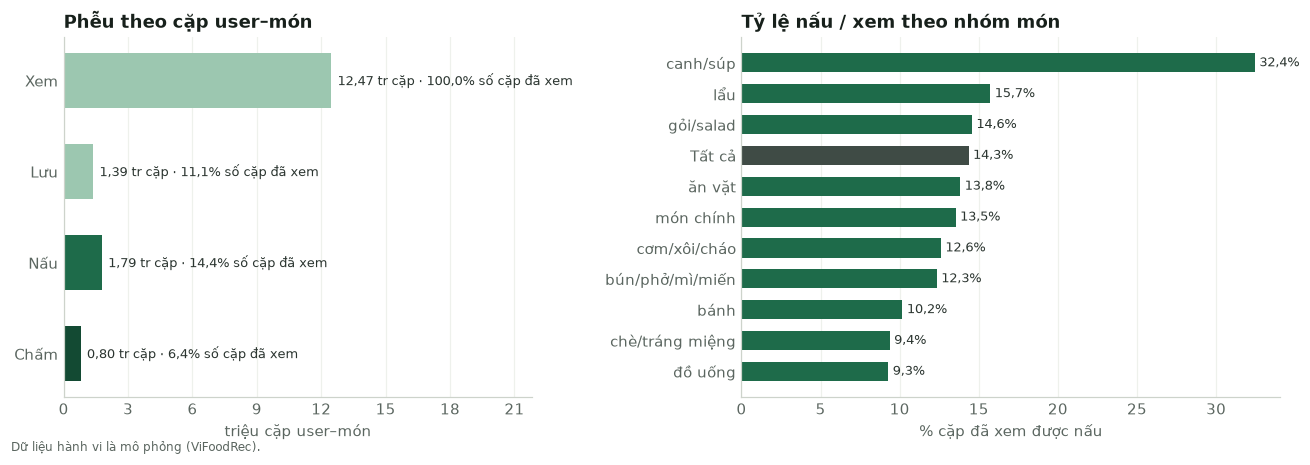

In [2]:
fun = A("funnel_by_category")
tot = fun[fun.dish_category == "Tất cả"].iloc[0]
stages = [("Xem", tot.view_pairs), ("Lưu", tot.favorite_pairs), ("Nấu", tot.cook_pairs), ("Chấm", tot.rate_pairs)]
cat = fun.sort_values("cook_per_view_pct")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})
names, vals = zip(*stages)
bars = a1.barh(names[::-1], [v / 1e6 for v in vals[::-1]], color=[C["herb_mid"], C["herb_mid"], C["herb"], C["herb_dark"]][::-1],
               height=0.6)
for b, v in zip(bars, vals[::-1]):
    a1.annotate(f"{fmt(v / 1e6, 2)} tr cặp · {fmt(100 * v / tot.view_pairs, 1)}% số cặp đã xem",
                (b.get_width(), b.get_y() + b.get_height() / 2), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=C["ink2"])
a1.set_xlim(0, tot.view_pairs / 1e6 * 1.75)
a1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a1.set_xlabel("triệu cặp user–món")
a1.grid(axis="y", visible=False); a1.grid(axis="x", visible=True)
a1.set_title("Phễu theo cặp user–món")
b2 = a2.barh(cat.dish_category, cat.cook_per_view_pct, height=0.62,
             color=[C["slate"] if c == "Tất cả" else C["herb"] for c in cat.dish_category])
bar_labels(a2, b2, nd=1, suffix="%", horizontal=True)
a2.set_xlabel("% cặp đã xem được nấu")
a2.grid(axis="y", visible=False); a2.grid(axis="x", visible=True)
a2.set_title("Tỷ lệ nấu / xem theo nhóm món")
fig.tight_layout()
save(fig, "05_pheu")
fun[["dish_category", "view_pairs", "favorite_per_view_pct", "cook_per_view_pct", "rate_per_cook_pct", "avg_rating"]]

## 2. Lượt nấu theo giờ × thứ
Giờ là giờ bắt đầu phiên (múi giờ Việt Nam). Cuối tuần gần gấp đôi ngày thường, đỉnh là CN 17–19h.

da ghi docs/images/nb_05_heatmap_gio_thu.png
luot nau trung binh moi ngay: ngay thuong 269.018 · cuoi tuan 518.876 (x1.93)


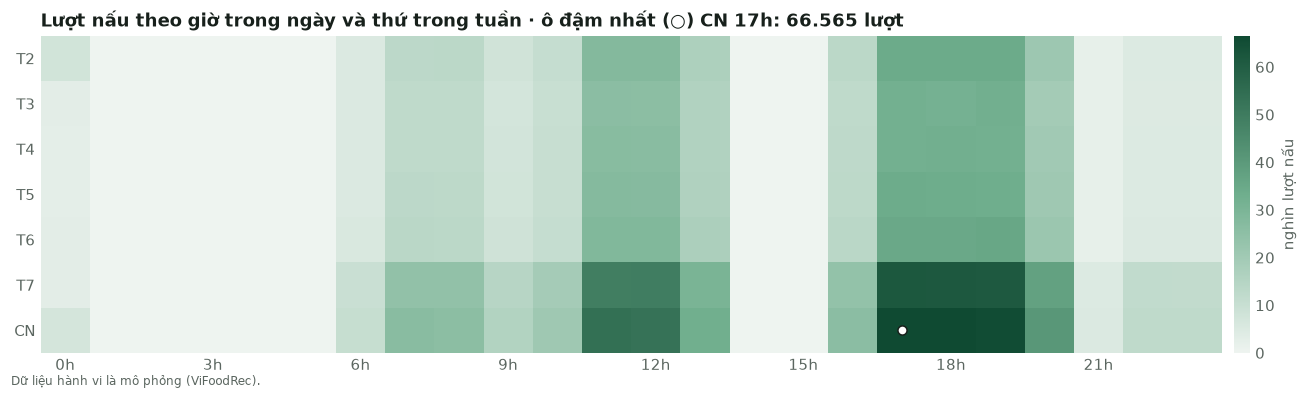

In [3]:
hm = A("heatmap_hour_dow")
order = hm.drop_duplicates("dow_idx").sort_values("dow_idx").dow_vn.tolist()
M = hm.pivot(index="dow_vn", columns="hour", values="cooks").loc[order]
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(M.values / 1000, cmap=SEQ, aspect="auto")
ax.set_yticks(range(len(order)), order)
ax.set_xticks(range(0, 24, 3), [f"{h}h" for h in range(0, 24, 3)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("nghìn lượt nấu", color=C["muted"]); cb.outline.set_visible(False)
peak = hm.loc[hm.cooks.idxmax()]
ax.plot([peak.hour], [order.index(peak.dow_vn)], "o", ms=6, mfc="white", mec=C["ink"], mew=1)
ax.set_title(f"Lượt nấu theo giờ trong ngày và thứ trong tuần · ô đậm nhất (○) {peak.dow_vn} {peak.hour}h: "
             f"{fmt(peak.cooks)} lượt")
fig.tight_layout()
save(fig, "05_heatmap_gio_thu")
wk = hm.assign(cuoi_tuan=hm.dow_idx >= 6).groupby("cuoi_tuan").cooks.sum() / hm.assign(cuoi_tuan=hm.dow_idx >= 6).groupby("cuoi_tuan").dow_idx.nunique()
print("luot nau trung binh moi ngay: ngay thuong", fmt(wk[False]), "· cuoi tuan", fmt(wk[True]), f"(x{wk[True] / wk[False]:.2f})")

## 3. Theo tháng: tổng lượt nấu và tỷ trọng món Tết
Tháng 02/2026 có Tết: món mùa "tết" chiếm khoảng 1/5 lượt nấu, các tháng khác khoảng 3%. Tháng 08 là validation, 09 là test.

da ghi docs/images/nb_05_theo_thang.png


,0,1,2,3,4,5,6,7,8,9,10,11
month,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
pct,3.44,3.4,3.43,6.06,19.17,3.74,3.52,3.19,3.09,3.29,3.22,3.51


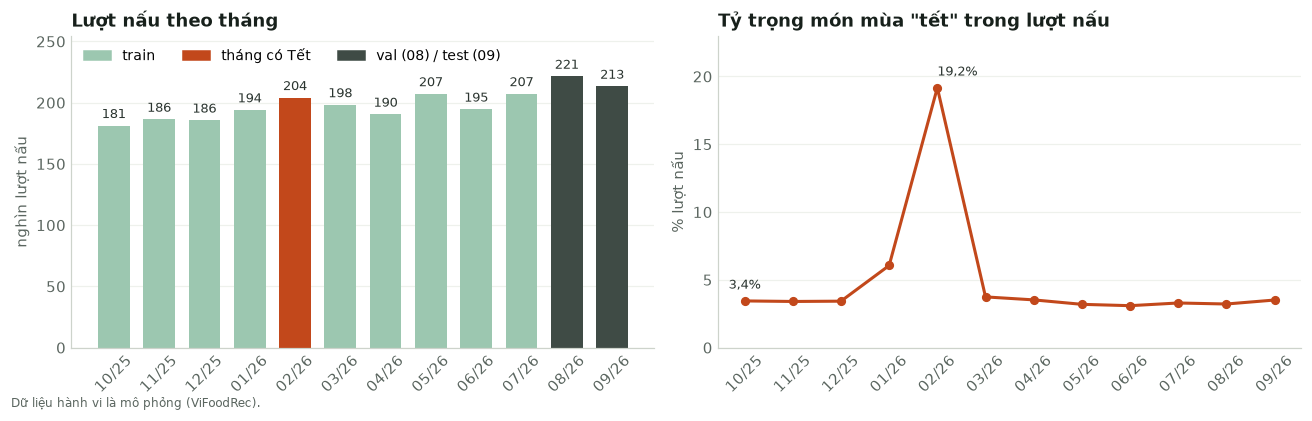

In [4]:
tr = A("trend_month_category")
mon = tr.groupby("month").cooks.sum().reset_index()
sm = A("season_month")
tet = sm.groupby(["month", "season"]).cooks.sum().unstack().fillna(0)
tet_share = (100 * tet["tết"] / tet.sum(axis=1)).reset_index(name="pct")
lab = [m[5:] + "/" + m[2:4] for m in mon.month]

def mcolor(m):
    return C["chili"] if m == "2026-02" else (C["slate"] if m >= "2026-08" else C["herb_mid"])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
b = a1.bar(lab, mon.cooks / 1000, color=[mcolor(m) for m in mon.month], width=0.7)
bar_labels(a1, b, nd=0)
a1.set_ylabel("nghìn lượt nấu"); a1.set_ylim(0, mon.cooks.max() / 1000 * 1.15)
a1.set_title("Lượt nấu theo tháng")
from matplotlib.patches import Patch
a1.legend(handles=[Patch(color=C["herb_mid"], label="train"), Patch(color=C["chili"], label="tháng có Tết"),
                   Patch(color=C["slate"], label="val (08) / test (09)")], loc="upper left", ncol=3)
a1.tick_params(axis="x", labelrotation=45)
a2.plot(lab, tet_share.pct, color=C["chili"], marker="o", ms=5)
for x, y in zip(lab, tet_share.pct):
    if y > 10 or x == lab[0]:
        a2.annotate(f"{fmt(y, 1)}%", (x, y), xytext=(0, 8), textcoords="offset points", fontsize=8.5, color=C["ink2"],
                    ha="center" if x == lab[0] else "left")
a2.set_ylim(0, tet_share.pct.max() * 1.2); a2.set_ylabel("% lượt nấu")
a2.set_title("Tỷ trọng món mùa \"tết\" trong lượt nấu")
a2.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
save(fig, "05_theo_thang")
tet_share.round(2).T

## 4. Đuôi dài: phần trăm món đầu bảng chiếm bao nhiêu lượt
Đường cong tích lũy (món xếp theo lượt nấu giảm dần). Gini lượt nấu là 0,698.

da ghi docs/images/nb_05_duoi_dai.png


'/home/jovyan/work/docs/images/nb_05_duoi_dai.png'

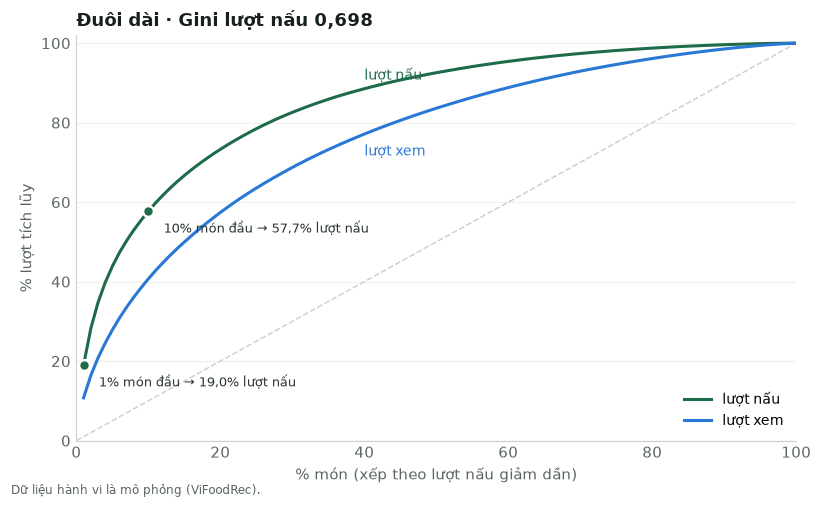

In [5]:
lt = A("long_tail_curve")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot([0, 100], [0, 100], color=C["line"], lw=1, ls="--")
ax.plot(lt.dish_pct, lt.cooks_cum_pct, color=C["herb"], label="lượt nấu")
ax.plot(lt.dish_pct, lt.views_cum_pct, color=C["blue"], label="lượt xem")
for p in (1, 10):
    r = lt[lt.dish_pct == p].iloc[0]
    ax.plot([p], [r.cooks_cum_pct], "o", color=C["herb"], ms=7, mec="white", mew=1.5)
    ax.annotate(f"{p}% món đầu → {fmt(r.cooks_cum_pct, 1)}% lượt nấu", (p, r.cooks_cum_pct), xytext=(10, -14),
                textcoords="offset points", fontsize=8.5, color=C["ink2"])
ax.annotate("lượt nấu", (40, lt[lt.dish_pct == 40].cooks_cum_pct.iloc[0]), xytext=(0, 6), textcoords="offset points",
            color=C["herb"], fontsize=9)
ax.annotate("lượt xem", (40, lt[lt.dish_pct == 40].views_cum_pct.iloc[0]), xytext=(0, -14), textcoords="offset points",
            color=C["blue"], fontsize=9)
ax.set_xlabel("% món (xếp theo lượt nấu giảm dần)"); ax.set_ylabel("% lượt tích lũy")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.legend(loc="lower right")
ax.set_title(f"Đuôi dài · Gini lượt nấu {fmt(rep.get('long_tail', {}).get('gini_cooks', 0.698), 3)}")
fig.tight_layout()
save(fig, "05_duoi_dai")

## 5. Lift theo nhóm người dùng
Lift = tỷ trọng của thuộc tính trong lượt nấu của nhóm / tỷ trọng chung. Lift > 1: nhóm nấu nhiều hơn mức chung.
Thang màu phân kỳ, giữa là 1 (thang log để 0,5 và 2 cách đều 1).

da ghi docs/images/nb_05_lift_vung.png


value,lẩu,chè/tráng miệng,bánh,ăn vặt,gỏi/salad,canh/súp,bún/phở/mì/miến,món chính,cơm/xôi/cháo,đồ uống
group_value,,,,,,,,,,
Bắc,1.05,0.91,0.95,1.01,0.96,1.02,1.02,1.01,1.01,0.99
Trung,1.17,0.93,0.96,1.06,1.04,0.96,1.01,1.02,0.94,1.00
Nam,0.89,1.10,1.06,0.97,1.01,1.00,0.98,0.99,1.01,1.01


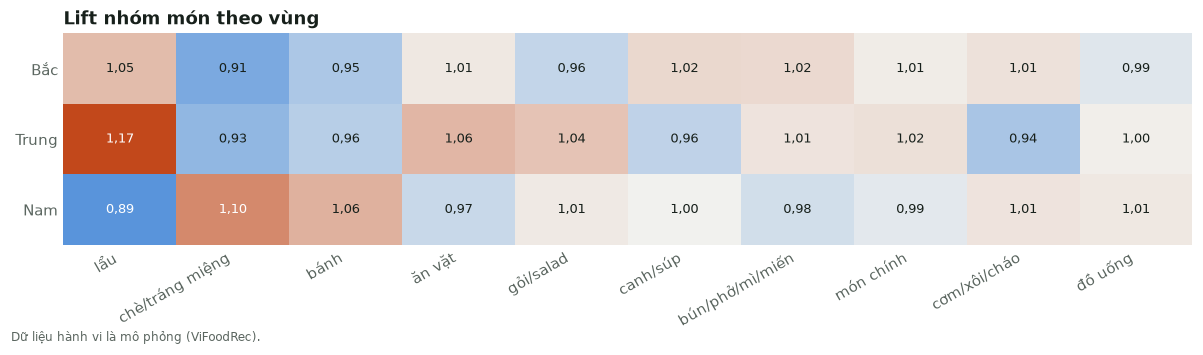

In [6]:
lift = A("lift_by_group")

def lift_heat(group_type, attribute, rows_order, title, name, figsize=(11, 3.2)):
    d = lift[(lift.group_type == group_type) & (lift.attribute == attribute)]
    M = d.pivot(index="group_value", columns="value", values="lift").loc[rows_order]
    M = M[M.max().sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=figsize)
    L = np.log2(M.values.astype(float))
    lim = max(abs(np.nanmin(L)), abs(np.nanmax(L)))
    im = ax.imshow(L, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(M.index)), M.index)
    ax.set_xticks(range(len(M.columns)), M.columns, rotation=30, ha="right")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            ax.text(j, i, fmt(v, 2), ha="center", va="center", fontsize=8.5,
                    color="white" if abs(np.log2(v)) > lim * 0.6 else C["ink"])
    ax.set_title(title)
    fig.tight_layout()
    save(fig, name)
    return M.round(2)

lift_heat("region", "dish_category", ["Bắc", "Trung", "Nam"], "Lift nhóm món theo vùng", "05_lift_vung")

da ghi docs/images/nb_05_lift_tuoi.png


value,đồ uống,chè/tráng miệng,gỏi/salad,ăn vặt,bánh,canh/súp,cơm/xôi/cháo,món chính,lẩu,bún/phở/mì/miến
group_value,,,,,,,,,,
18-24,2.02,1.83,1.60,1.57,1.49,0.65,1.18,0.80,1.11,0.92
25-34,1.03,1.00,1.19,1.01,1.06,0.90,1.19,0.97,1.14,1.07
35-44,0.66,0.70,0.70,0.88,0.78,1.10,0.82,1.14,0.91,0.87
45+,0.44,0.61,0.50,0.60,0.72,1.39,0.74,1.06,0.79,1.13


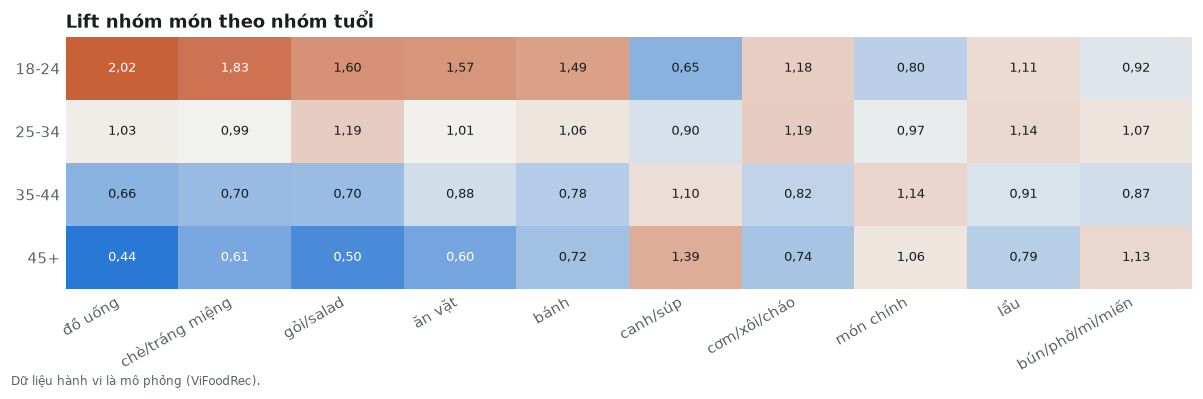

In [7]:
lift_heat("age_group", "dish_category", ["18-24", "25-34", "35-44", "45+"], "Lift nhóm món theo nhóm tuổi", "05_lift_tuoi",
          figsize=(11, 3.6))

da ghi docs/images/nb_05_lift_bua.png


value,ăn vặt,chè/tráng miệng,đồ uống,bánh,bún/phở/mì/miến,lẩu,cơm/xôi/cháo,canh/súp,gỏi/salad,món chính
group_value,,,,,,,,,,
sáng,0.72,1.60,3.85,2.80,2.80,0.80,1.56,0.27,0.81,0.56
trưa,0.33,0.65,0.30,0.34,0.76,0.34,0.72,1.26,1.15,1.14
tối,0.36,0.66,0.33,0.60,0.69,1.34,1.07,1.16,1.03,1.10
khuya,10.14,4.05,3.15,3.28,0.39,1.96,0.44,0.18,0.50,0.50


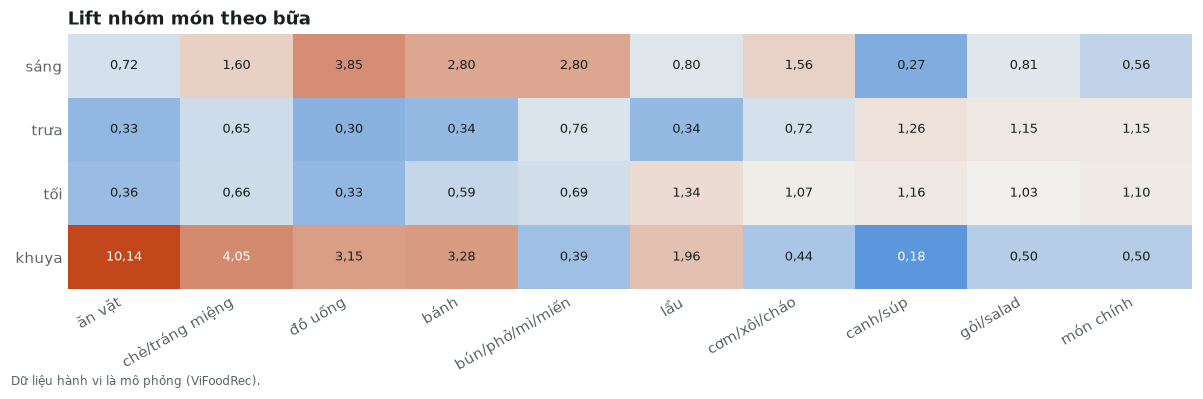

In [8]:
lift_heat("meal_slot", "dish_category", ["sáng", "trưa", "tối", "khuya"], "Lift nhóm món theo bữa", "05_lift_bua",
          figsize=(11, 3.6))

In [9]:
top = (lift[lift.cooks >= 1000].assign(nhom=lambda d: d.group_type + "=" + d.group_value)
       .sort_values("lift", ascending=False).groupby("group_type").head(3))
top[["nhom", "attribute", "value", "cooks", "share_pct", "overall_pct", "lift"]]

,nhom,attribute,value,cooks,share_pct,overall_pct,lift
234,meal_slot=khuya,dish_category,ăn vặt,18564,12.79,1.26,10.142
235,meal_slot=khuya,dish_category,chè/tráng miệng,19624,13.52,3.34,4.051
291,meal_slot=sáng,main_method,pha/xay,34258,9.95,2.58,3.858
18,age_group=18-24,main_method,pha/xay,23897,5.22,2.58,2.023
10,age_group=18-24,dish_type_fixed,Đồ uống,24624,5.38,2.67,2.017
0,age_group=18-24,dish_category,đồ uống,24624,5.38,2.67,2.017
156,day_type=cuối tuần,dish_category,lẩu,34253,3.30,2.14,1.542
484,region=Trung,is_spicy,true,162693,34.33,25.23,1.361
496,region=Trung,main_protein,thịt khác,2812,0.59,0.48,1.230
184,day_type=cuối tuần,main_protein,thịt khác,5863,0.56,0.48,1.171


## 6. Mâm cơm, nấu lại, điểm chấm, mức hoạt động

da ghi docs/images/nb_05_mam_com.png


'/home/jovyan/work/docs/images/nb_05_mam_com.png'

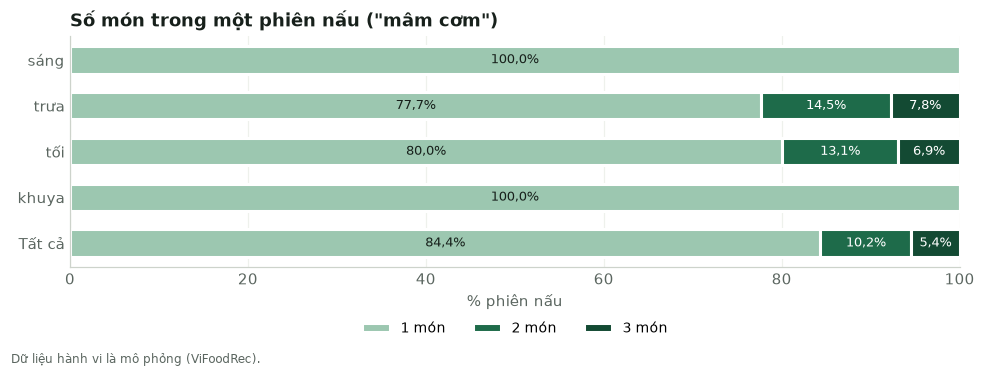

In [10]:
ss = A("session_size")
slots = ["sáng", "trưa", "tối", "khuya", "Tất cả"]
P = ss.pivot(index="meal_slot", columns="size", values="share_pct").reindex(slots).fillna(0)
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(P))
for size, col in zip(["1", "2", "3"], [C["herb_mid"], C["herb"], C["herb_dark"]]):
    b = ax.barh(P.index, P[size], left=left, color=col, height=0.6, edgecolor="white", linewidth=2,
                label=f"{size} món")
    for rect, v, l0 in zip(b, P[size], left):
        if v >= 4:
            ax.text(l0 + v / 2, rect.get_y() + rect.get_height() / 2, f"{fmt(v, 1)}%", ha="center", va="center",
                    fontsize=8.5, color="white" if size != "1" else C["ink"])
    left += P[size].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% phiên nấu")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
ax.set_title("Số món trong một phiên nấu (\"mâm cơm\")")
fig.tight_layout()
save(fig, "05_mam_com")

da ghi docs/images/nb_05_nau_lai_diem_hoat_dong.png


'/home/jovyan/work/docs/images/nb_05_nau_lai_diem_hoat_dong.png'

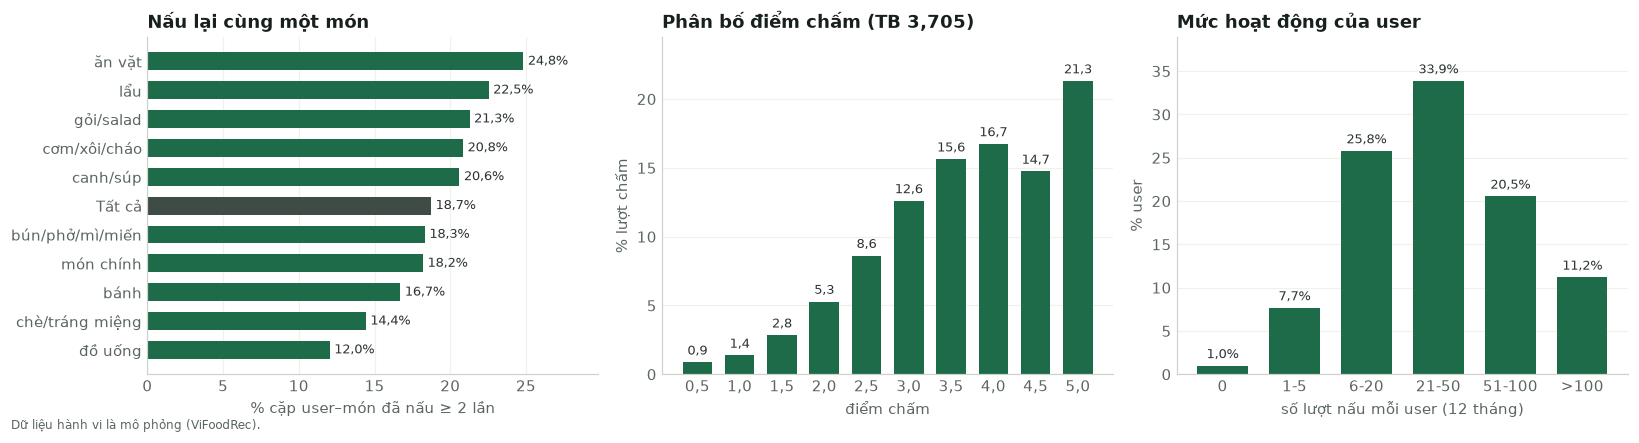

In [11]:
rp = A("repeat_by_category").sort_values("repeat_pct")
rd = A("rating_dist")
ua = A("user_activity").sort_values("ord")
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
b = a1.barh(rp.dish_category, rp.repeat_pct, height=0.62,
            color=[C["slate"] if c == "Tất cả" else C["herb"] for c in rp.dish_category])
bar_labels(a1, b, nd=1, suffix="%", horizontal=True)
a1.set_xlim(0, rp.repeat_pct.max() * 1.2); a1.grid(axis="y", visible=False); a1.grid(axis="x", visible=True)
a1.set_xlabel("% cặp user–món đã nấu ≥ 2 lần"); a1.set_title("Nấu lại cùng một món")
b = a2.bar([fmt(r, 1) for r in rd.rating], rd.share_pct, color=C["herb"], width=0.7)
bar_labels(a2, b, nd=1)
a2.set_xlabel("điểm chấm"); a2.set_ylabel("% lượt chấm"); a2.set_ylim(0, rd.share_pct.max() * 1.15)
a2.set_title("Phân bố điểm chấm (TB 3,705)")
b = a3.bar(ua.cooks_per_user, ua.share_pct, color=C["herb"], width=0.7)
bar_labels(a3, b, nd=1, suffix="%")
a3.set_xlabel("số lượt nấu mỗi user (12 tháng)"); a3.set_ylabel("% user"); a3.set_ylim(0, ua.share_pct.max() * 1.15)
a3.set_title("Mức hoạt động của user")
fig.tight_layout()
save(fig, "05_nau_lai_diem_hoat_dong")

## 7. Nguyên liệu và danh mục

da ghi docs/images/nb_05_nguyen_lieu_danh_muc.png


,value,n_dishes,catalog_pct,cook_pct,cooks_per_dish,lift
9,ăn vặt,80,1.45,1.26,375.6,0.869
8,lẩu,117,2.13,2.14,435.9,1.005
7,đồ uống,235,4.27,2.67,270.3,0.625
6,chè/tráng miệng,398,7.24,3.34,199.8,0.461
5,cơm/xôi/cháo,250,4.55,3.50,333.9,0.769
4,bún/phở/mì/miến,367,6.67,5.58,362.4,0.837
3,bánh,979,17.80,8.33,202.6,0.468
2,gỏi/salad,300,5.46,8.77,696.4,1.606
1,canh/súp,341,6.20,20.43,1427.4,3.295
0,món chính,2432,44.23,43.99,431.0,0.995


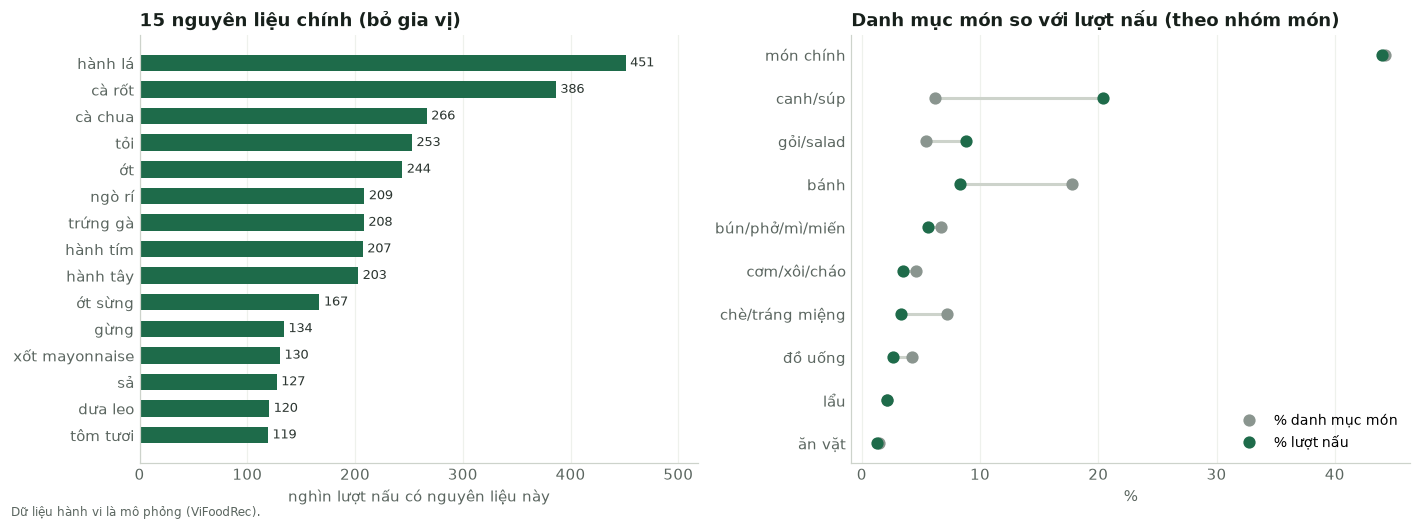

In [12]:
ing = A("top_ingredients")
ti = ing[~ing.is_seasoning].nsmallest(15, "cook_rank").sort_values("cooks")
cv = A("catalog_vs_cooked")
cc = cv[cv.attribute == "dish_category"].sort_values("cook_pct")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
b = a1.barh(ti.ingredient, ti.cooks / 1e3, color=C["herb"], height=0.62)
bar_labels(a1, b, nd=0, horizontal=True)
a1.grid(axis="y", visible=False); a1.grid(axis="x", visible=True)
a1.set_xlim(0, ti.cooks.max() / 1e3 * 1.15)
a1.set_xlabel("nghìn lượt nấu có nguyên liệu này"); a1.set_title("15 nguyên liệu chính (bỏ gia vị)")
y = np.arange(len(cc))
a2.hlines(y, cc.catalog_pct, cc.cook_pct, color=C["line"], lw=2)
a2.plot(cc.catalog_pct, y, "o", color=C["neutral"], ms=7, label="% danh mục món")
a2.plot(cc.cook_pct, y, "o", color=C["herb"], ms=7, label="% lượt nấu")
a2.set_yticks(y, cc.value)
a2.grid(axis="y", visible=False); a2.grid(axis="x", visible=True)
a2.set_xlabel("%"); a2.legend(loc="lower right")
a2.set_title("Danh mục món so với lượt nấu (theo nhóm món)")
fig.tight_layout()
save(fig, "05_nguyen_lieu_danh_muc")
cc[["value", "n_dishes", "catalog_pct", "cook_pct", "cooks_per_dish", "lift"]]

## 8. Món đứng đầu theo bữa (theo lượt nấu; `rk_lift` là hạng theo lift)

In [13]:
td = A("top_dish_by_slot")
td[td.rk <= 5].sort_values(["meal_slot", "rk"])[["meal_slot", "rk", "rk_lift", "dish_name", "dish_category", "cooks", "share_pct", "lift"]]

,meal_slot,rk,rk_lift,dish_name,dish_category,cooks,share_pct,lift
0,khuya,1,16,Tôm Nướng Muối Tiêu Xiên Que,ăn vặt,7461,5.14,9.883
1,khuya,2,3,Bánh Tráng Nướng Chảo,ăn vặt,2362,1.63,12.010
2,khuya,3,37,Bánh Mì Nướng Muối Ớt,bánh,1949,1.34,5.729
3,khuya,4,141,Lẩu ghẹ kim chi,lẩu,1648,1.14,2.120
4,khuya,5,14,Chả tôm xiên que nướng mè,ăn vặt,1424,0.98,11.256
19,sáng,1,118,Mì Quảng xào lươn,bún/phở/mì/miến,2816,0.82,2.668
20,sáng,2,52,Salad Ức Gà Bánh Mì,gỏi/salad,2217,0.64,3.384
21,sáng,3,40,Chè Thạch Sữa Chua,chè/tráng miệng,2214,0.64,3.646
22,sáng,4,30,Latte Ngũ Cốc,đồ uống,1973,0.57,3.774
23,sáng,5,194,Canh hào thanh mát,canh/súp,1935,0.56,0.391
